# Customer Churn / Sales Trend Analysis
**InternCircle · Data Science & AI · Project 03**

## 1. The business question
A manager wants to know:
1. Which **months** and **categories** earn the most revenue?
2. Who are our **best customers**, and how concentrated is revenue?
3. Which customers are going **quiet** (churn risk)?
4. What should we **do next**?

**Data note:** the data is *simulated* (generated with a fixed random seed, so results are reproducible). No real customer data is used. Assumptions built into the simulation: a festive-season (Oct-Dec) lift, category-specific order values, and uneven customer activity. Findings describe this made-up dataset, not a real company.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.1f}".format)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "axes.grid.axis": "y"})
PRIMARY, ACCENT = "#1F4E79", "#C8102E"

## 2. Create the data and check it

In [2]:
SEED, N_ORDERS, N_CUSTOMERS = 42, 5000, 400
CATEGORIES = ["Electronics", "Fashion", "Home", "Books"]
CAT_PROBS = [0.30, 0.35, 0.20, 0.15]
CAT_SCALE = {"Electronics": 900, "Fashion": 450, "Home": 600, "Books": 250}
MONTH_WEIGHT = np.array([0.9, 0.85, 0.9, 0.95, 1.0, 1.0, 0.95, 1.0, 1.1, 1.25, 1.4, 1.35])

rng = np.random.default_rng(SEED)
cust_weight = rng.pareto(1.6, N_CUSTOMERS) + 1          # uneven customer activity
cust_weight /= cust_weight.sum()
customer_id = rng.choice(np.arange(1, N_CUSTOMERS + 1), N_ORDERS, p=cust_weight)

days = pd.date_range("2025-01-01", "2025-12-31", freq="D")
day_w = MONTH_WEIGHT[days.month - 1]; day_w = day_w / day_w.sum()
order_date = rng.choice(days, N_ORDERS, p=day_w)

category = rng.choice(CATEGORIES, N_ORDERS, p=CAT_PROBS)
scale = np.array([CAT_SCALE[x] for x in category])
amount = (rng.gamma(2.0, 1.0, N_ORDERS) * scale / 2).round(2)

orders = pd.DataFrame({"order_id": np.arange(1, N_ORDERS + 1), "order_date": order_date,
                       "customer_id": customer_id, "category": category, "amount": amount}
                     ).sort_values("order_date", ignore_index=True)
orders["order_id"] = np.arange(1, len(orders) + 1)
orders.head()

,order_id,order_date,customer_id,category,amount
0,1,2025-01-01,92,Electronics,"1,812.8"
1,2,2025-01-01,120,Electronics,197.6
2,3,2025-01-01,97,Home,194.2
3,4,2025-01-01,395,Electronics,468.6
4,5,2025-01-01,357,Fashion,434.5


In [3]:
print("Shape:", orders.shape)
print("Missing values:", int(orders.isna().sum().sum()))
print("Duplicate rows:", int(orders.duplicated().sum()))
print(orders.dtypes)
orders["amount"].describe()

Shape: (5000, 5)
Missing values: 0
Duplicate rows: 0
order_id                int64
order_date     datetime64[us]
customer_id             int64
category                  str
amount                float64
dtype: object


count   5,000.0
mean      595.2
std       503.8
min         7.1
25%       239.2
50%       449.3
75%       794.5
max     4,008.5
Name: amount, dtype: float64

## 3. Date features
Convert the date column and create month, weekday and quarter columns.

In [4]:
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders["month"] = orders["order_date"].dt.to_period("M")
orders["weekday"] = orders["order_date"].dt.day_name()
orders["quarter"] = "Q" + orders["order_date"].dt.quarter.astype(str)
orders[["order_date", "month", "weekday", "quarter"]].head()

,order_date,month,weekday,quarter
0,2025-01-01,2025-01,Wednesday,Q1
1,2025-01-01,2025-01,Wednesday,Q1
2,2025-01-01,2025-01,Wednesday,Q1
3,2025-01-01,2025-01,Wednesday,Q1
4,2025-01-01,2025-01,Wednesday,Q1


## 4. Monthly revenue trend and growth

In [5]:
monthly = orders.groupby("month")["amount"].sum()
growth = (monthly.pct_change() * 100).round(1)
trend = pd.DataFrame({"revenue": monthly.round(0), "mom_growth_%": growth})
best_m, worst_m = monthly.idxmax(), monthly.idxmin()
print(f"Best month : {best_m}  ({monthly.max():,.0f})")
print(f"Worst month: {worst_m}  ({monthly.min():,.0f})")
print(f"Best / worst ratio: {monthly.max()/monthly.min():.2f}x")
trend

Best month : 2025-11  (323,295)
Worst month: 2025-02  (186,836)
Best / worst ratio: 1.73x


,revenue,mom_growth_%
month,,
2025-01,"215,401.0",NaN
2025-02,"186,836.0",-13.3
2025-03,"210,237.0",12.5
2025-04,"222,644.0",5.9
2025-05,"246,319.0",10.6
2025-06,"236,164.0",-4.1
2025-07,"204,721.0",-13.3
2025-08,"265,444.0",29.7
2025-09,"268,624.0",1.2


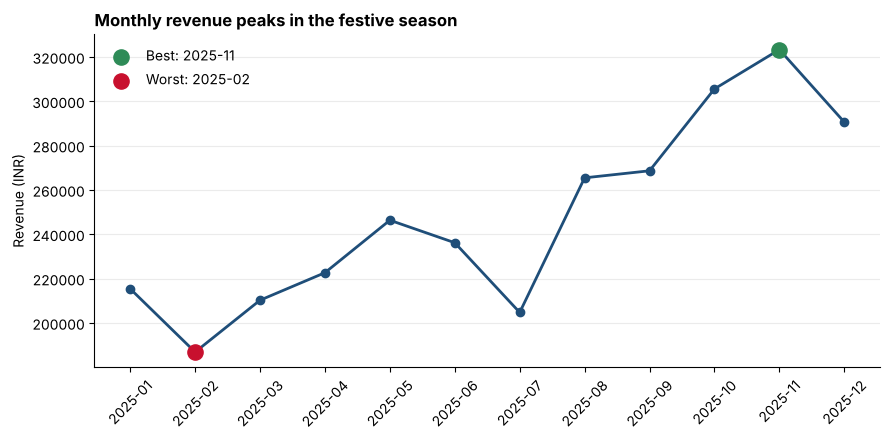

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = monthly.index.astype(str)
ax.plot(x, monthly.values, marker="o", color=PRIMARY, lw=2)
ax.scatter([str(best_m)], [monthly.max()], color="#2E8B57", s=120, zorder=5, label=f"Best: {best_m}")
ax.scatter([str(worst_m)], [monthly.min()], color=ACCENT, s=120, zorder=5, label=f"Worst: {worst_m}")
ax.set_title("Monthly revenue peaks in the festive season", loc="left", fontweight="bold")
ax.set_ylabel("Revenue (INR)"); ax.tick_params(axis="x", rotation=45); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

In [7]:
quarterly = orders.groupby("quarter")["amount"].sum()
print((quarterly / quarterly.sum() * 100).round(1).rename("share of revenue %"))

quarter
Q1   20.6
Q2   23.7
Q3   24.8
Q4   30.9
Name: share of revenue %, dtype: float64


## 5. Compare categories (groupby + pivot table)

In [8]:
by_cat = (orders.groupby("category")["amount"]
          .agg(total="sum", average="mean", orders="count")
          .sort_values("total", ascending=False))
by_cat["share_%"] = by_cat["total"] / by_cat["total"].sum() * 100
by_cat.round(1)

,total,average,orders,share_%
category,,,,
Electronics,"1,360,854.4",912.1,1492,45.7
Fashion,"792,886.5",452.8,1751,26.6
Home,"642,773.0",621.6,1034,21.6
Books,"179,316.7",248.0,723,6.0


In [9]:
pivot = orders.pivot_table(index="month", columns="category", values="amount",
                           aggfunc="sum", fill_value=0)[by_cat.index.tolist()]
pivot.round(0)

category,Electronics,Fashion,Home,Books
month,,,,
2025-01,"95,020.0","58,399.0","48,450.0","13,533.0"
2025-02,"90,907.0","41,013.0","43,953.0","10,964.0"
2025-03,"102,928.0","58,457.0","36,188.0","12,664.0"
2025-04,"96,456.0","64,118.0","47,093.0","14,978.0"
2025-05,"109,111.0","56,174.0","68,338.0","12,697.0"
2025-06,"107,864.0","61,210.0","52,173.0","14,918.0"
2025-07,"93,106.0","50,761.0","48,685.0","12,169.0"
2025-08,"136,408.0","65,048.0","48,473.0","15,515.0"
2025-09,"120,258.0","87,830.0","48,394.0","12,142.0"


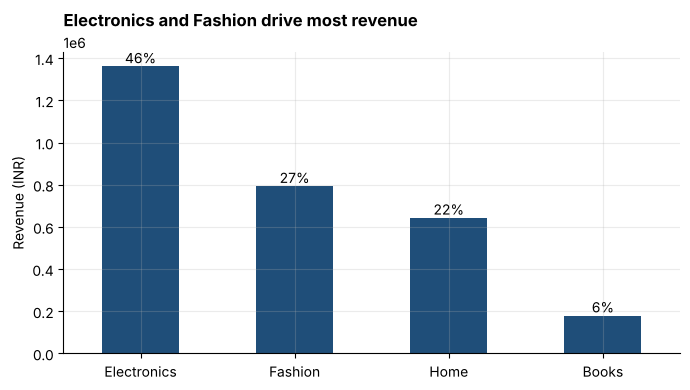

In [10]:
ax = by_cat["total"].plot(kind="bar", color=PRIMARY, figsize=(7, 4), rot=0)
for i, s in enumerate(by_cat["share_%"]):
    ax.text(i, by_cat["total"].iloc[i], f"{s:.0f}%", ha="center", va="bottom")
ax.set_title("Electronics and Fashion drive most revenue", loc="left", fontweight="bold")
ax.set_ylabel("Revenue (INR)"); ax.set_xlabel(""); plt.tight_layout(); plt.show()

## 6. Best customers: the 80/20 (Pareto) test

In [11]:
spend = orders.groupby("customer_id")["amount"].sum().sort_values(ascending=False)
n_cust = len(spend)
top10_share = spend.head(n_cust // 10).sum() / spend.sum()
top20_share = spend.head(n_cust // 5).sum() / spend.sum()
cum = spend.cumsum() / spend.sum()
n_for_80 = int((cum < 0.8).sum() + 1)
print(f"Top 10% of customers ({n_cust//10}) bring {top10_share:.1%} of revenue")
print(f"Top 20% of customers ({n_cust//5}) bring {top20_share:.1%} of revenue")
print(f"{n_for_80} customers ({n_for_80/n_cust:.0%} of the base) are needed to reach 80% of revenue")

Top 10% of customers (40) bring 36.2% of revenue
Top 20% of customers (80) bring 51.5% of revenue
202 customers (50% of the base) are needed to reach 80% of revenue


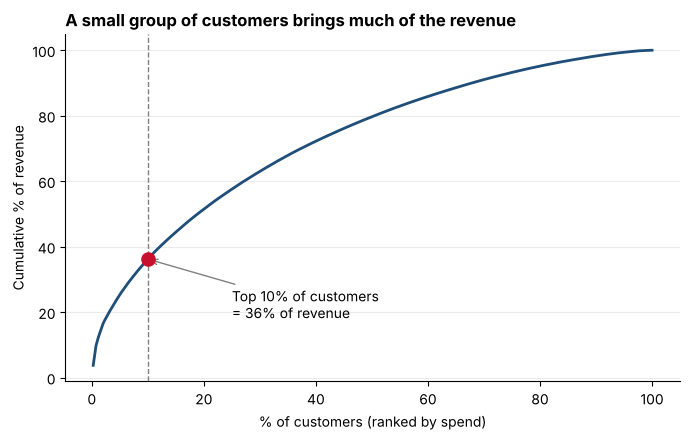

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, n_cust + 1) / n_cust * 100, cum.values * 100, color=PRIMARY, lw=2)
ax.axvline(10, color="grey", ls="--", lw=1); ax.scatter([10], [top10_share * 100], color=ACCENT, s=90, zorder=5)
ax.annotate(f"Top 10% of customers\n= {top10_share:.0%} of revenue", xy=(10, top10_share * 100),
            xytext=(25, top10_share * 100 - 18), arrowprops=dict(arrowstyle="->", color="grey"))
ax.set_xlabel("% of customers (ranked by spend)"); ax.set_ylabel("Cumulative % of revenue")
ax.set_title("A small group of customers brings much of the revenue", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

In [13]:
cust = orders.groupby("customer_id").agg(total_spend=("amount", "sum"), orders=("order_id", "count"),
                                         last_order=("order_date", "max")).sort_values("total_spend", ascending=False)
rank = np.arange(len(cust))
cust["segment"] = np.where(rank < n_cust // 10, "Top 10%", np.where(rank < n_cust * 0.5, "Middle 40%", "Bottom 50%"))
seg = cust.groupby("segment").agg(customers=("total_spend", "size"), revenue=("total_spend", "sum"), avg_orders=("orders", "mean"))
seg["revenue_share_%"] = seg["revenue"] / seg["revenue"].sum() * 100
seg.round(1)

,customers,revenue,avg_orders,revenue_share_%
segment,,,,
Bottom 50%,200,"604,371.8",6.0,20.3
Middle 40%,160,"1,294,348.1",12.6,43.5
Top 10%,40,"1,077,110.7",44.5,36.2


## 7. Churn view: who has gone quiet?
A customer is flagged *at risk* if their last order was more than 90 days before the end of the data.

In [14]:
snapshot = orders["order_date"].max() + pd.Timedelta(days=1)
cust["days_since_last"] = (snapshot - cust["last_order"]).dt.days
cust["churn_risk"] = cust["days_since_last"] > 90
print(f"At-risk customers: {cust['churn_risk'].sum()} of {n_cust} ({cust['churn_risk'].mean():.1%})")
risk = cust.groupby("segment").agg(customers=("churn_risk", "size"), at_risk=("churn_risk", "sum"))
risk["at_risk_%"] = risk["at_risk"] / risk["customers"] * 100
risk.round(1)

At-risk customers: 35 of 400 (8.8%)


,customers,at_risk,at_risk_%
segment,,,
Bottom 50%,200,33,16.5
Middle 40%,160,2,1.2
Top 10%,40,0,0.0


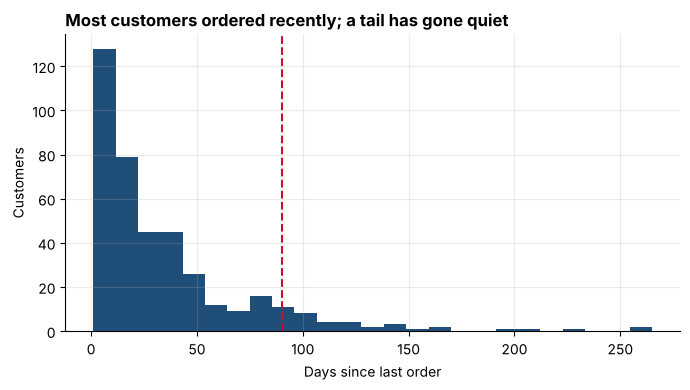

In [15]:
ax = cust["days_since_last"].plot(kind="hist", bins=25, color=PRIMARY, figsize=(7, 4))
ax.axvline(90, color=ACCENT, ls="--"); ax.set_xlabel("Days since last order"); ax.set_ylabel("Customers")
ax.set_title("Most customers ordered recently; a tail has gone quiet", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 8. Recommendations
See `reports/business_brief.md` for the one-page version. In short:

1. **Protect and grow the top 10%** (40 customers, 36.2% of revenue) with a loyalty offer. None of them is currently at churn risk, so the goal is retention, not win-back.
2. **Win back the quiet low spenders** with a targeted offer: 35 customers (8.8%) have not ordered in 90+ days, and 33 of them are in the bottom 50% segment.
3. **Plan stock and campaigns around Oct-Dec**: Q4 brings the most revenue, and November is the best month, 1.73x the worst month (February).

*All numbers refer to the simulated dataset above.*